# El trilema macroeconómico en Costa Rica y el papel de las reservas internacionales, 1999-2025

Recorrido por el análisis del artículo. Toda la lógica está en el paquete `trilema` (`src/trilema/`), y cada cifra de los cuadros del artículo se comprueba en `tests/test_replica_articulo.py`. La primera celda corre el análisis completo desde los datos crudos y guarda la base, las tablas y las figuras.

In [1]:
import sys
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))  # para usar el paquete sin instalarlo
from trilema import modelos as md
from trilema.flujo import ejecutar, guardar

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}", "display.max_columns", 30)
res = ejecutar()
guardar(res)
FIG = RAIZ / "outputs" / "figures"
res.base.head()

,IM,EC,AF,inflacion,crecimiento_pib,apertura_comercial,terminos_intercambio,vix,tasa_efr,ri_pib,ri_pib_norm
trimestre,,,,,,,,,,,
1999Q1,0.5111,0.9648,0.1427,11.1900,2.2334,0.8925,105.5575,27.2500,4.7300,0.2968,0.0000
1999Q2,0.3856,0.9809,0.5218,9.7071,5.2820,0.9420,106.4215,24.4000,4.7500,0.4393,0.4156
1999Q3,0.1025,0.9763,0.1524,8.0820,5.0436,0.8750,104.0569,23.3200,5.1000,0.4003,0.3019
1999Q4,0.6558,0.9887,0.2067,9.3926,3.8201,0.8033,106.4480,22.6600,5.3000,0.3779,0.2364
2000Q1,0.6172,0.9820,0.3773,10.4446,5.5086,0.8902,98.9315,23.1500,5.6800,0.3781,0.2370


## 1. Índices

| Índice | Construcción |
|---|---|
| Independencia monetaria (IM) | `(1 - corr(i_CR, i_US)) / 2`, con datos semanales dentro de cada trimestre (tasa MEDI y Treasury Bills a 3 meses) |
| Estabilidad cambiaria (EC) | `0.01 / (0.01 + sd(Δ ln e))`, con el tipo de cambio semanal CRC/USD |
| Apertura financiera (AF) | Flujos de la balanza de pagos sobre el PIB, normalizados entre 0 y 1 |
| Reservas (RI/PIB) | Reservas internacionales netas sobre el PIB trimestral, normalizadas para la restricción del cuadrilema |

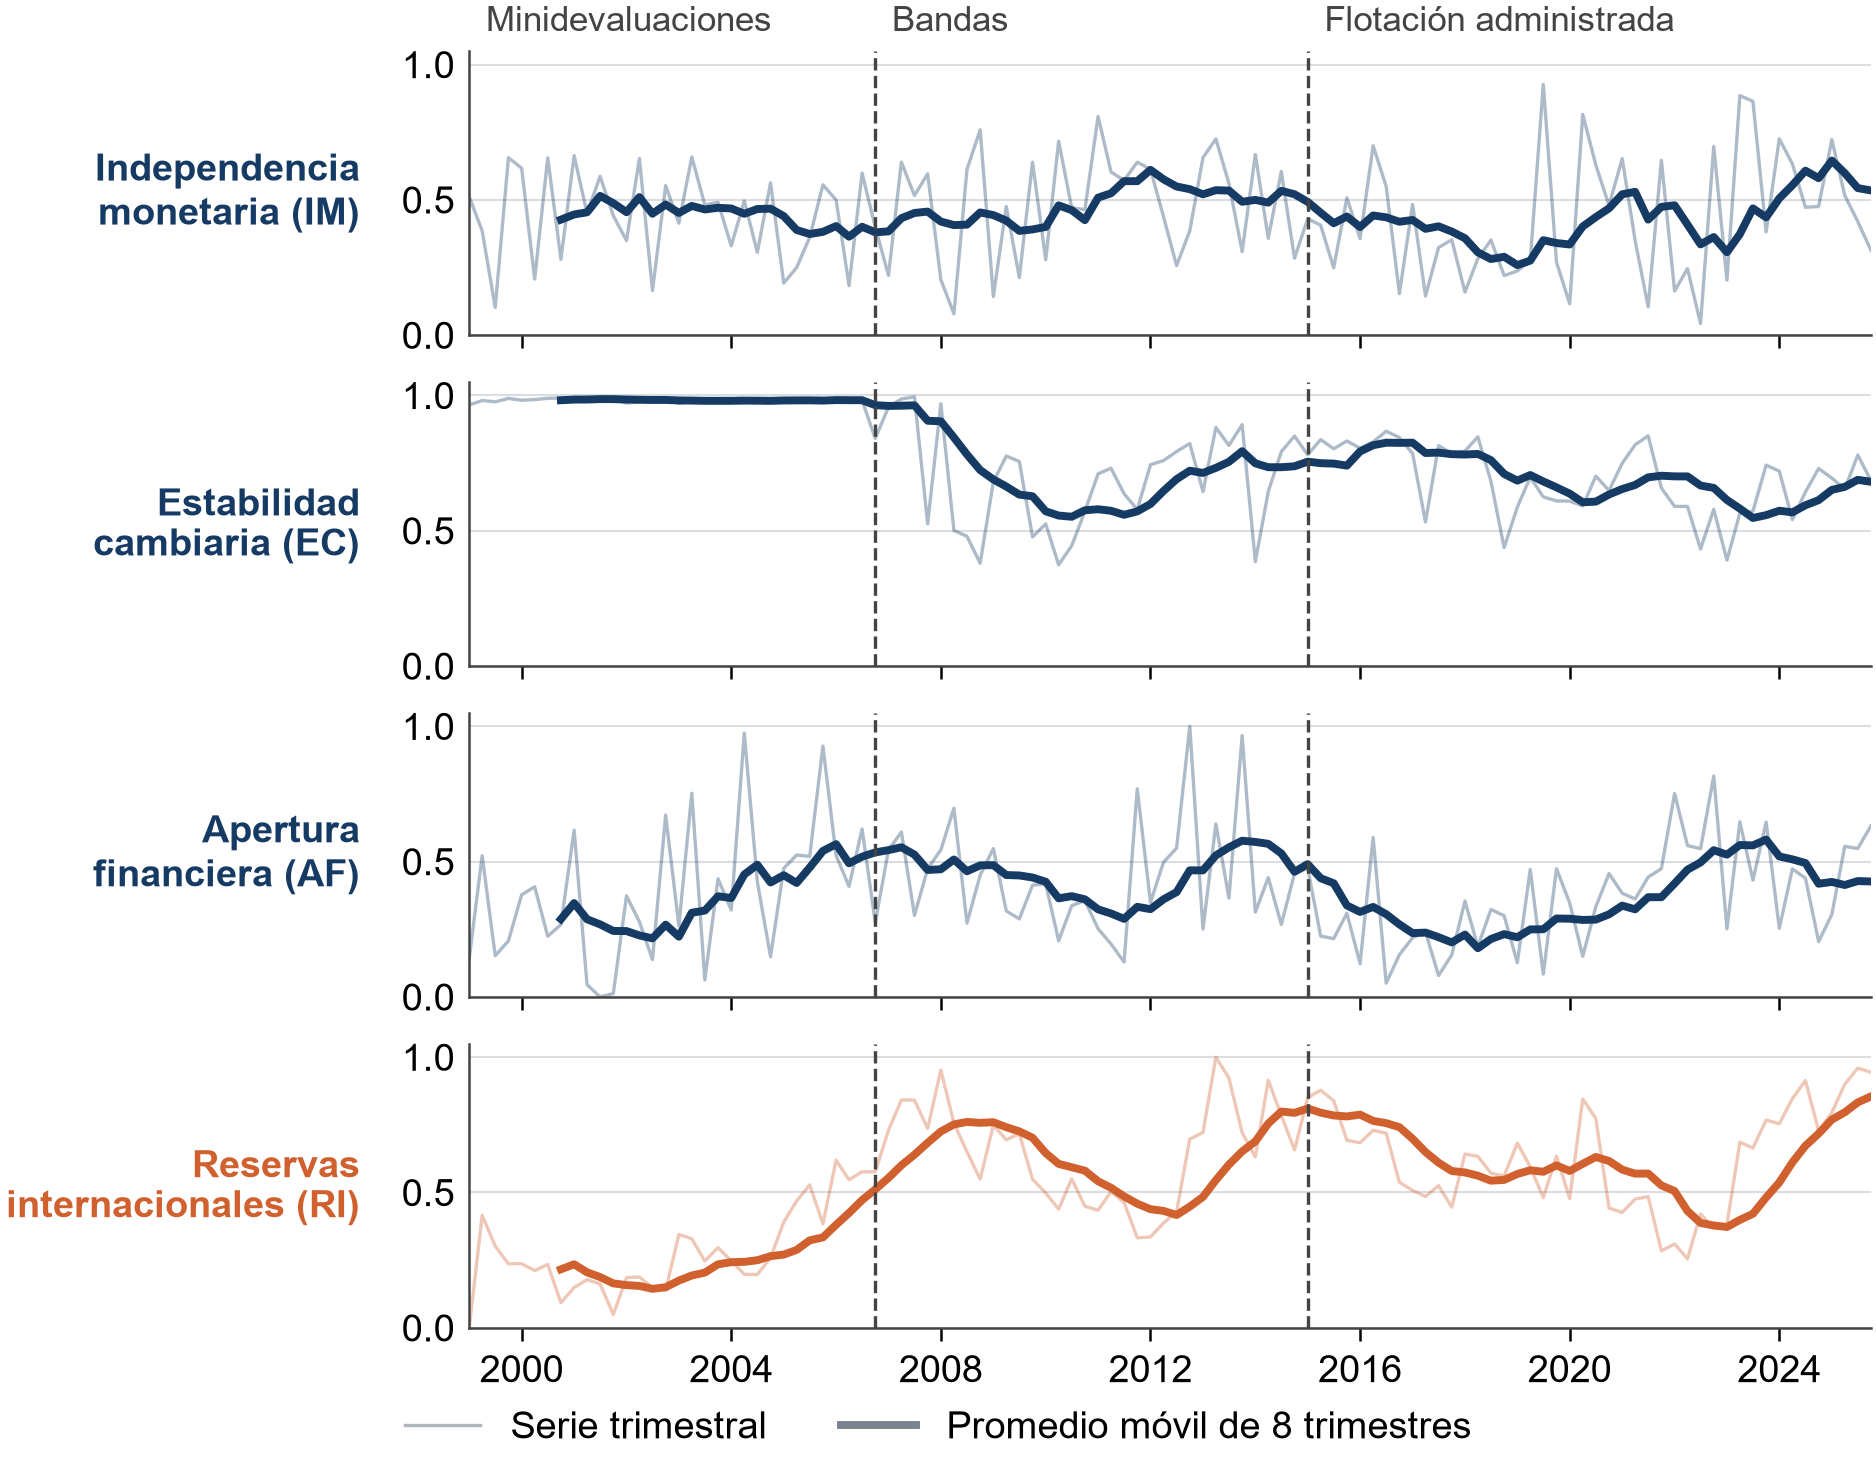

,count,mean,std,min,25%,50%,75%,max
IM,108.0000,0.4490,0.2034,0.0427,0.2799,0.4672,0.6140,0.9263
EC,108.0000,0.7748,0.1836,0.3739,0.6413,0.7924,0.9767,0.9946
AF,108.0000,0.3932,0.2139,0.0000,0.2479,0.3695,0.5227,1.0000
ri_pib_norm,108.0000,0.5312,0.2396,0.0000,0.3423,0.5329,0.7213,1.0000
inflacion,108.0000,5.7129,4.5151,-2.6359,1.7221,5.2556,9.7132,14.4005


In [2]:
display(Image(FIG / "indices_trilema.png", width=760))
res.base[["IM", "EC", "AF", "ri_pib_norm", "inflacion"]].describe().T

## 2. Pruebas previas

La inflación es I(1), lo que motiva estimar en primeras diferencias la regresión sobre la inflación.

In [3]:
display(res.raiz_unitaria[["variable", "p_adf", "p_kpss", "p_adf_primera_dif", "orden"]])
display(res.johansen)
res.granger.pivot(index="variable", columns="rezagos", values="p")

,variable,p_adf,p_kpss,p_adf_primera_dif,orden
0,Inflación,0.8404,0.0100,0.0004,I(1)
1,IM,0.0000,0.1000,0.0000,I(0)
2,EC,0.2344,0.0100,0.0000,I(1)
3,AF,0.0544,0.1000,0.0000,Ambiguo
4,RI/PIB,0.0286,0.0100,0.0000,Ambiguo
5,Crecimiento del PIB,0.0003,0.1000,0.0000,I(0)
6,Términos de intercambio,0.5821,0.0172,0.1616,I(1)
7,Apertura comercial,0.6012,0.0100,0.0006,I(1)


,h0_rango,traza,critico_traza_5,rechaza_traza,max_valor_propio,critico_max_5,rechaza_max
0,r <= 0,69.0888,47.8545,True,40.1483,27.5858,True
1,r <= 1,28.9404,29.7961,False,16.8351,21.1314,False
2,r <= 2,12.1053,15.4943,False,9.8535,14.2639,False
3,r <= 3,2.2519,3.8415,False,2.2519,3.8415,False


rezagos,1,2,4
variable,,,
AF,0.4742,0.6689,0.4455
Apertura comercial,0.0008,0.0012,0.0053
Crecimiento del PIB,0.0042,0.0558,0.2182
EC,0.0948,0.0249,0.0030
IM,0.5155,0.8984,0.9505
RI/PIB,0.0882,0.2724,0.7021
Términos de intercambio,0.0623,0.0552,0.0035


Quiebres en la media de cada serie, con una búsqueda secuencial al estilo de Bai y Perron.

In [4]:
res.quiebres

,IM,EC,AF,RI/PIB,Inflación
Quiebre 1,2016Q4,2005Q1,2002Q4,2002Q3,2009Q3
Quiebre 2,2019Q3,2007Q4,2014Q1,2005Q2,2012Q1
Quiebre 3,2023Q2,2011Q1,2020Q4,2023Q2,2015Q2


## 3. Restricción del trilema

`2 = b1 IM + b2 EC + b3 AF + e`, sin intercepto y con errores HAC. En minidevaluaciones EC es casi constante, así que el R² = 1 es un artefacto algebraico y la referencia es la muestra robusta (2006Q4 a 2025Q4).

In [5]:
MUESTRAS = ["Minidevaluaciones", "Bandas", "Flotación administrada", "Robusta"]


def cuadro(modelos, variables):
    t = md.tabla_restriccion(modelos, variables)
    return t.pivot(index="variable", columns="muestra", values="coef").loc[variables, MUESTRAS]


cuadro(res.trilema, md.TRILEMA)

muestra,Minidevaluaciones,Bandas,Flotación administrada,Robusta
variable,,,,
IM,-0.0155,1.3918,0.2968,0.8043
EC,2.0431,1.3652,2.2204,1.9063
AF,0.0028,0.7426,0.8222,0.6530


## 4. Restricción ampliada con las reservas (cuadrilema)

In [6]:
cuadro(res.cuadrilema, md.CUADRILEMA)

muestra,Minidevaluaciones,Bandas,Flotación administrada,Robusta
variable,,,,
IM,-0.0159,1.2615,0.2207,0.7071
EC,2.0436,0.9096,2.0083,1.5968
AF,0.0033,0.5958,0.7888,0.5860
ri_pib_norm,-0.0020,0.7012,0.3072,0.4541


## 5. Participación de cada componente

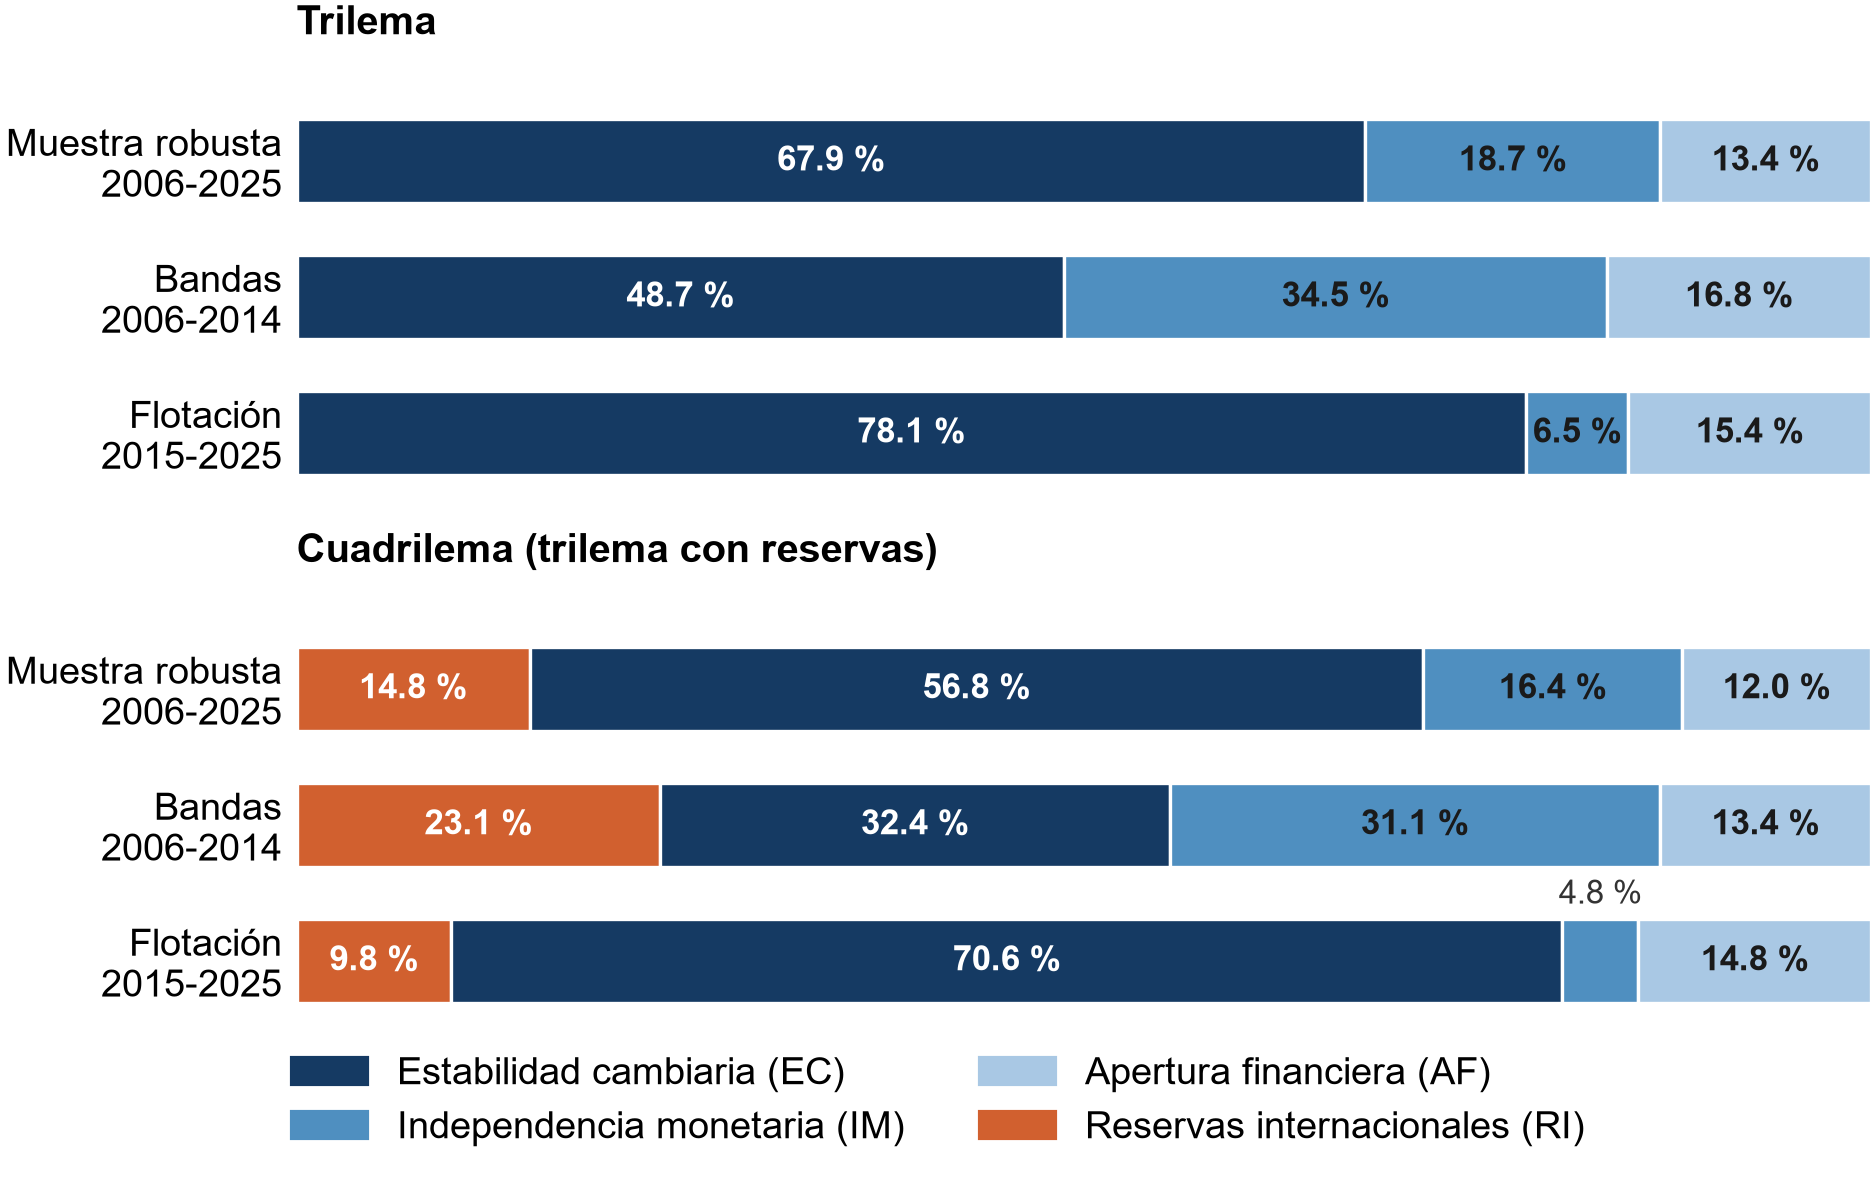

,IM,EC,AF
Minidevaluaciones,0.3400,99.6080,0.0521
Bandas,34.4901,48.7452,16.7648
Flotación administrada,6.5142,78.0759,15.4099
Robusta,18.7367,67.8771,13.3862
Completa,20.9140,66.3635,12.7225


,IM,EC,AF,ri_pib_norm
Minidevaluaciones,0.3480,99.5625,0.0622,0.0272
Bandas,31.1463,32.3595,13.4015,23.0926
Flotación administrada,4.8415,70.5645,14.7716,9.8224
Robusta,16.4464,56.7640,11.9923,14.7973
Completa,14.3052,58.9139,6.4996,20.2813


In [7]:
display(Image(FIG / "participacion_trilema_cuadrilema.png", width=720))
display(res.part_trilema)
res.part_cuadrilema

## 6. Reservas e inflación

En primeras diferencias, con errores HAC. Las reservas mantienen una asociación negativa y significativa con la inflación, y la apertura comercial, una positiva.

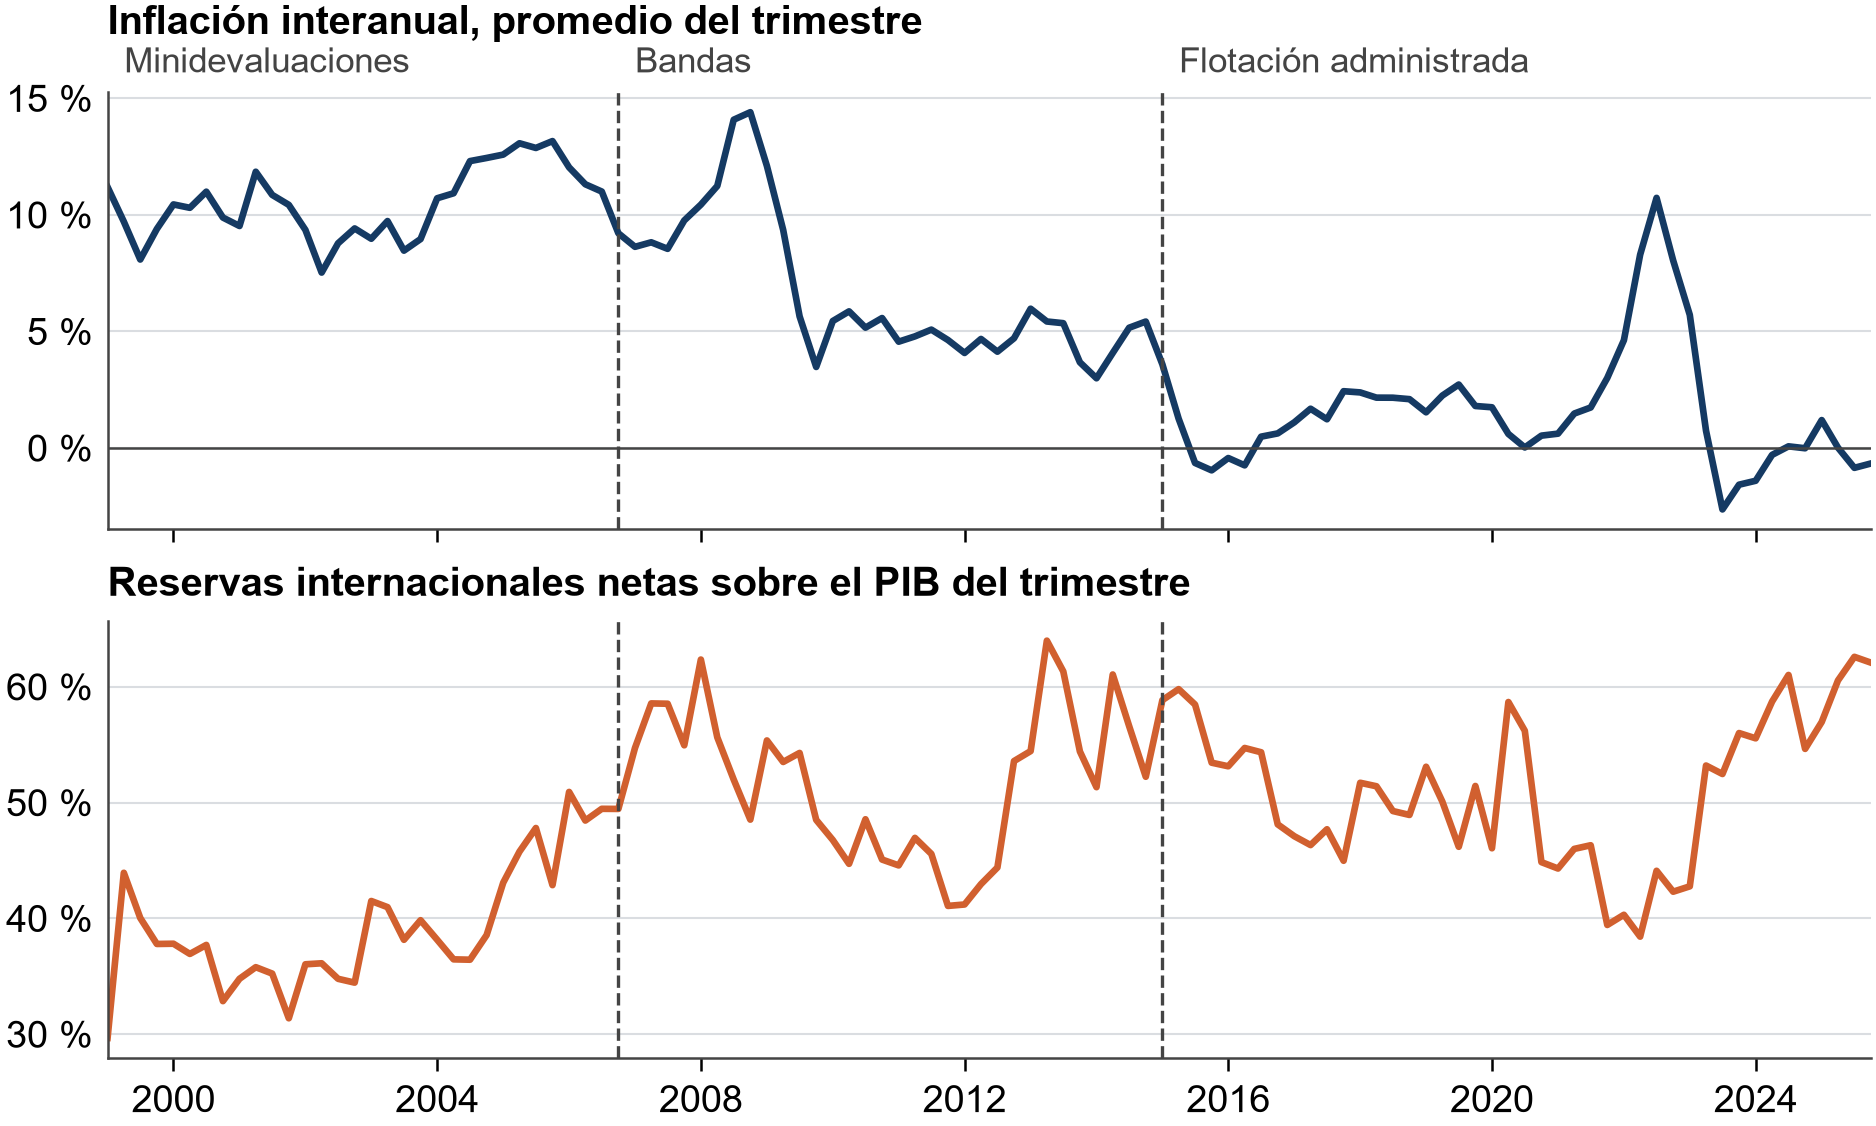

modelo,A: EC + IM,B: EC + AF,C: IM + AF
variable,,,
const,-0.0715,-0.0706,-0.0699
d_AF,NaN,-0.1301,-0.1372
d_EC,-0.2096,-0.1212,NaN
d_IM,-0.2266,NaN,-0.2178
d_apertura_comercial,8.5884,8.7843,8.7628
d_crecimiento_pib,-0.1060,-0.1032,-0.1071
d_ri_pib,-6.4046,-6.2157,-6.4616
d_tasa_efr,-0.0639,-0.0715,-0.0659
d_terminos_intercambio,0.0090,0.0127,0.0127


In [8]:
display(Image(FIG / "inflacion_y_reservas.png", width=720))
t = md.tabla_modelos(res.pares)
t.pivot(index="variable", columns="modelo", values="coef")

In [9]:
t.pivot(index="variable", columns="modelo", values="p")

modelo,A: EC + IM,B: EC + AF,C: IM + AF
variable,,,
const,0.5668,0.5741,0.5804
d_AF,NaN,0.7436,0.7317
d_EC,0.7984,0.8843,NaN
d_IM,0.6610,NaN,0.6658
d_apertura_comercial,0.0029,0.0027,0.0021
d_crecimiento_pib,0.1185,0.1330,0.1225
d_ri_pib,0.0152,0.0215,0.0194
d_tasa_efr,0.8371,0.8205,0.8328
d_terminos_intercambio,0.8036,0.7532,0.7491


## 7. Interacciones con las reservas

Las variables se centran antes de multiplicarlas. Las interacciones se estiman primero para cada vértice por separado y luego dentro de cada par de vértices. La de IM con las reservas es negativa y significativa al 5 % en las tres especificaciones que la incluyen; las de EC y AF no son significativas en ninguna.

In [10]:
def solo_reservas(tabla):
    return tabla.query("variable.str.contains('_x_') or variable == 'd_ri_pib'")


solo_reservas(md.tabla_modelos(res.interacciones))

,modelo,variable,coef,se,p,n,r2
2,IM,d_ri_pib,-6.1876,2.1874,0.0047,107,0.2026
3,IM,IM_x_RI,-20.9148,9.7618,0.0322,107,0.2026
11,EC,d_ri_pib,-5.9914,2.6088,0.0216,107,0.1487
12,EC,EC_x_RI,-10.8848,21.6436,0.6150,107,0.1487
20,AF,d_ri_pib,-6.3213,2.3093,0.0062,107,0.1466
21,AF,AF_x_RI,-0.1818,10.1975,0.9858,107,0.1466


In [11]:
solo_reservas(md.tabla_modelos(res.interacciones_pares))

,modelo,variable,coef,se,p,n,r2
1,A: EC + IM,d_ri_pib,-5.1712,2.6274,0.0491,107,0.2137
3,A: EC + IM,EC_x_RI,-22.0238,18.7327,0.2397,107,0.2137
5,A: EC + IM,IM_x_RI,-22.8937,9.2964,0.0138,107,0.2137
12,B: EC + AF,d_ri_pib,-5.9916,2.5629,0.0194,107,0.1493
14,B: EC + AF,EC_x_RI,-10.7201,20.3741,0.5988,107,0.1493
16,B: EC + AF,AF_x_RI,0.8255,9.2025,0.9285,107,0.1493
23,C: IM + AF,d_ri_pib,-5.5815,2.2490,0.0131,107,0.2043
25,C: IM + AF,IM_x_RI,-21.2855,9.8853,0.0313,107,0.2043
27,C: IM + AF,AF_x_RI,-3.7289,9.6085,0.6980,107,0.2043


## 8. Sensibilidad con variables instrumentales

Los instrumentos son rezagos de una serie persistente, así que el resultado se toma solo como sensibilidad y no identifica un efecto causal.

In [12]:
pd.Series(res.iv)

coef_iv            -1.7555
se_iv               3.0138
p_iv                0.5602
n                 106.0000
f_primera_etapa    65.4684
p_hausman           0.2205
p_sargan            0.0341
dtype: float64

## 9. Reservas sobre el PIB, 1960-2024

La figura del anexo del artículo, con datos anuales del Banco Mundial.

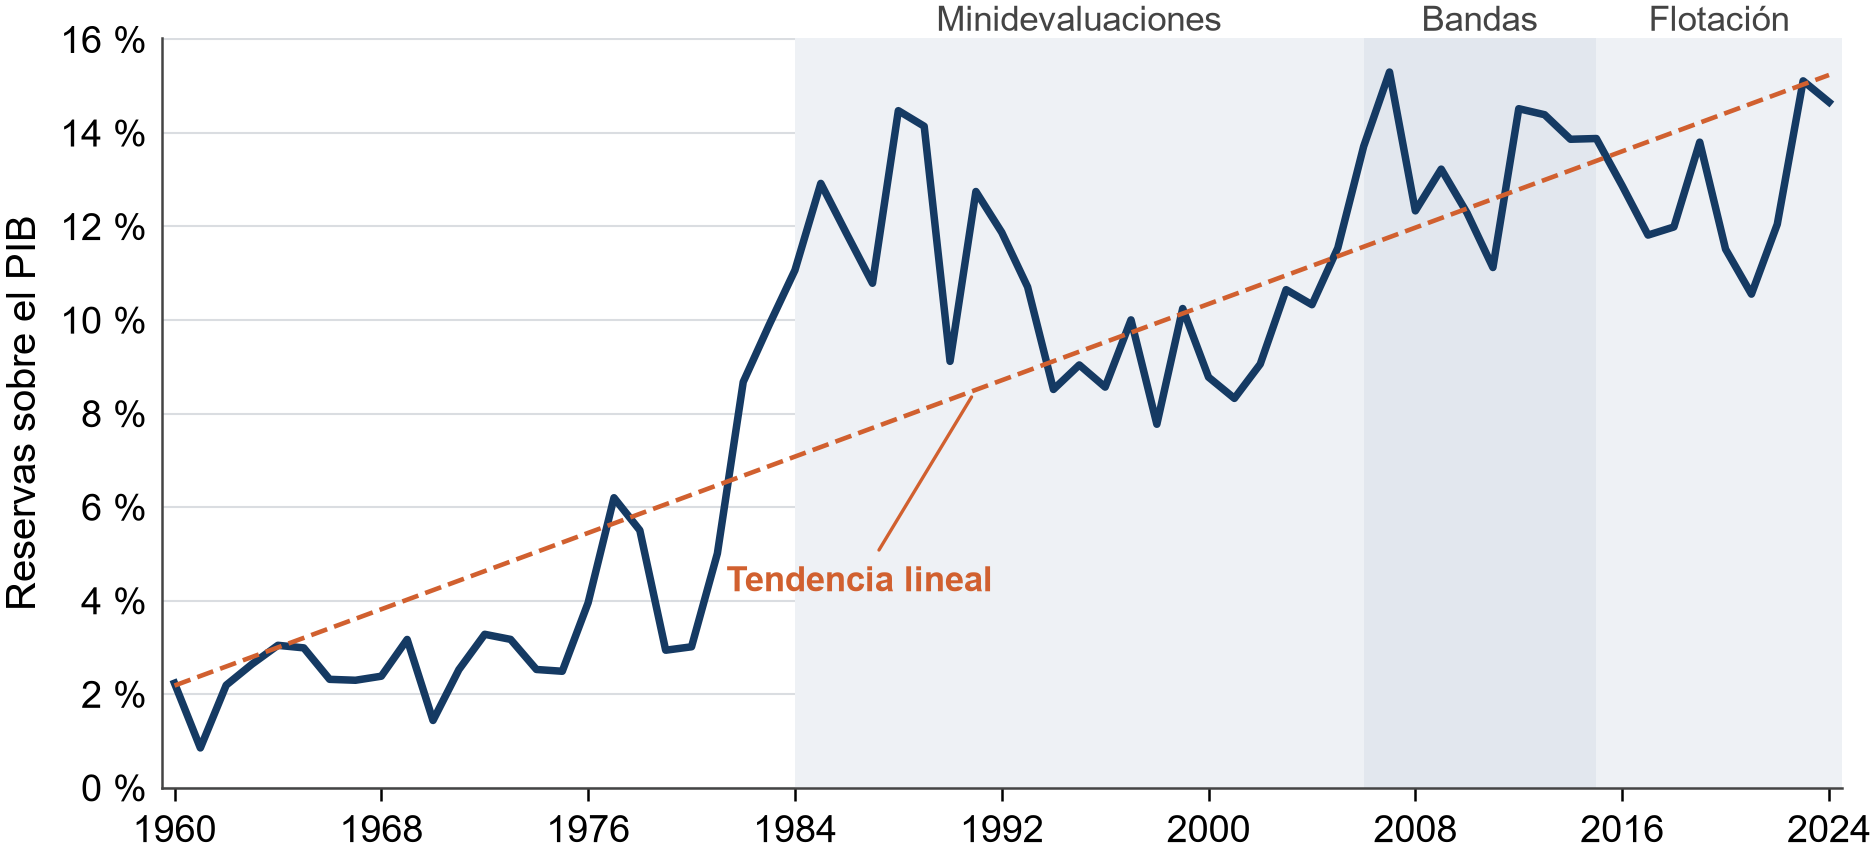

count   65.0000
mean     8.7109
std      4.5092
min      0.8505
25%      3.1714
50%     10.0029
75%     12.2873
max     15.3010
Name: ri_pib, dtype: float64

In [13]:
display(Image(FIG / "reservas_pib_1960_2024.png", width=720))
res.reservas_anuales["ri_pib"].describe()